# Чекпоинт 2. Разведочный анализ внешних данных: торговля и финансирование

**Зачем этот ноутбук.** Мы проверяем, отражает ли котировка Pink Sheet цены реальных сделок, ищем шоки предложения (например, сокращение экспорта из Китая), оцениваем стоимость доставки и стоимость денег в цепочке поставок. По итогам мы решаем, какие из этих данных пойдут в признаки модели.

| Раздел | Источник | Содержание |
|---|---|---|
| 1 | UN Comtrade | Покрытие и задержки публикации, выбросы, сверка с котировкой, экспорт Китая, крупнейшие экспортёры, стоимость доставки (разница CIF и FOB) |
| 2 | SEC EDGAR, FRED, BIS | Дни оборотного капитала, ставки, затраты на финансирование, доля этих затрат в марже, валютные курсы |
| 3 | все источники | Выводы и их использование в проекте |

Периоды те же, что в ноутбуке 01: трейн охватывает период с апреля 2015 по сентябрь 2023 года, тест охватывает период с октября 2023 по сентябрь 2026 года.

## 1. Торговля карбамидом: UN Comtrade

**Задача.** Изучить базу UN Comtrade, то есть данные ООН о международной торговле карбамидом, и понять, чем она полезна проекту.

**Данные.** Месячная торговля восьми стран со всем миром с 2015 по 2026 год. Данные загружены скриптом src/data/load_comtrade.py через бесплатный пробный доступ к API (preview) и сохранены в файл data/raw/comtrade_urea_monthly.csv.
- Экспортёры: Саудовская Аравия, Оман, Египет, Китай, Катар.
- Импортёры: Индия, Бразилия, США.

Каждая строка содержит страну, месяц, направление потока (X означает экспорт, M означает импорт), вес нетто и стоимость. У импорта стоимость указана на условиях CIF, то есть с доставкой и страховкой, а у экспорта на условиях FOB, то есть без доставки. Средняя цена тонны равна стоимости, делённой на вес.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

trade = pd.read_csv("../data/raw/comtrade_urea_monthly.csv", parse_dates=["date"])
pink = pd.read_parquet("../data/processed/prices_monthly.parquet")["urea_price"]
print("Строк:", len(trade), "| стран:", trade["country"].nunique(), "|", trade["date"].min().date(), "–", trade["date"].max().date())
trade.head()

Строк: 1628 | стран: 8 | 2015-01-01 – 2026-08-01


,country,reporterCode,period,flowCode,netWgt,qty,qtyUnitCode,altQty,altQtyUnitCode,isNetWgtEstimated,primaryValue,cifvalue,fobvalue,date,tonnes,usd_per_tonne
0,Бразилия,76,201501,M,201593668.0,201593668.0,8,201593668.0,8,False,7.383399e+07,7.383399e+07,68860991.0,2015-01-01,201593.668,366.251533
1,Оман,512,201501,M,78720.0,78720.0,8,78720.0,8,False,2.254304e+05,2.254304e+05,0.0,2015-01-01,78.720,2863.699301
2,Индия,699,201501,M,781378000.0,0.0,-1,0.0,-1,False,2.185051e+08,2.185051e+08,0.0,2015-01-01,781378.000,279.640689
3,Египет,818,201501,M,4937100.0,4937100.0,8,4937100.0,8,False,1.474940e+06,1.474940e+06,0.0,2015-01-01,4937.100,298.746297
4,США,842,201501,M,0.0,0.0,-1,0.0,-1,False,2.693606e+08,2.693606e+08,0.0,2015-01-01,NaN,NaN


### 1.1. Покрытие и задержка публикации
Comtrade собирает данные из таможенных отчётов стран. Поэтому данные приходят с задержкой, и не все страны отчитываются каждый месяц.

In [2]:
coverage = trade.groupby(["country", "flowCode"]).agg(
    первый_месяц=("date", "min"),
    последний_месяц=("date", "max"),
    месяцев=("date", "count"),
    без_веса=("tonnes", lambda s: s.isna().sum()),
)
coverage["задержка, мес. (от сентября 2026)"] = (
    (pd.Timestamp("2026-09-01") - coverage["последний_месяц"]).dt.days / 30.4
).round().astype(int)
coverage

первый_месяц последний_месяц  месяцев  без_веса  \
country           flowCode                                                   
Бразилия          M          2015-01-01      2026-08-01      140        14   
                  X          2015-01-01      2026-08-01      140         1   
Египет            M          2015-01-01      2026-06-01       68         2   
                  X          2015-01-01      2026-06-01      138         0   
Индия             M          2015-01-01      2026-08-01      140        14   
                  X          2015-01-01      2026-08-01      131         4   
Катар             M          2015-02-01      2023-12-01       18         1   
Китай             M          2016-01-01      2024-12-01      108        16   
                  X          2016-01-01      2024-12-01      108         3   
Оман              M          2015-01-01      2026-05-01       72         2   
                  X          2015-01-01      2026-05-01       82         0   
США               M          2015-01-01      2026-08-01      140        12   
                  X          2015-01-01      2026-08-01      140        48   
Саудовская Аравия M          2016-04-01      2026-04-01       70         5   
                  X          2015-01-01      2026-04-01      133         0   

                            задержка, мес. (от сентября 2026)  
country           flowCode                                     
Бразилия          M                                         1  
                  X                                         1  
Египет            M                                         3  
                  X                                         3  
Индия             M                                         1  
                  X                                         1  
Катар             M                                        33  
Китай             M                                        21  
                  X                                        21  
Оман              M                                         4  
                  X                                         4  
США               M                                         1  
                  X                                         1  
Саудовская Аравия M                                         5  
                  X                                         5

**Главный результат: данные Comtrade публикуются с задержкой от одного до пяти месяцев, поэтому как признак в реальном времени они не подходят.**

- Быстрее всех данные публикуют США, Бразилия и Индия: данные есть до августа 2026 года, задержка составляет один месяц.
- Египет опубликовал данные до июня 2026 года, Оман до мая, Саудовская Аравия до апреля 2026 года. Задержка у этих стран составляет от трёх до пяти месяцев.
- По Китаю данные есть только до декабря 2024 года. Катар не публикует помесячный экспорт совсем. Россия с 2022 года почти не публикует таможенную статистику, поэтому её данные мы не загружали.
- В 122 строках не указан вес, в основном это экспорт США и ранние годы. Цену тонны для этих строк мы не считаем.

**Следствие для модели.** Для прогноза на 1 и 3 месяца данные Comtrade нельзя использовать как признак в реальном времени, потому что они приходят позже, чем нужен прогноз. Эти данные можно использовать для проверки других данных, для разметки событий и для анализа структуры рынка. Как признак их можно использовать только с запаздыванием, которое не меньше задержки публикации.

### 1.2. Ошибочные значения и выбросы
Одна строка Comtrade показывает всю торговлю страны карбамидом за месяц в одном направлении. Цена тонны в строке равна стоимости, делённой на вес. Котировка Pink Sheet описывает оптовый удобрительный карбамид, который перевозят судами по 30 или 50 тысяч тонн. Если за месяц у страны набралось всего несколько сотен тонн, это не партия удобрения, а мелкие поставки другого товара.

**Гипотеза.** Мелкие потоки (до 1 000 тонн в месяц) имеют цену, не сопоставимую с котировкой, потому что в них попадает специальный карбамид мелкими партиями, а при малом весе любая неточность в данных сильно искажает цену тонны.

**Как проверяем.** Сравнивать минимум и максимум цен нельзя: их задаёт одна крайняя строка, а сами цены с 2015 по 2026 год менялись в несколько раз. Поэтому каждую строку мы делим на котировку Pink Sheet за тот же месяц и сравниваем распределения этого отношения у крупных и мелких потоков.

In [3]:
big = trade[(trade["tonnes"] > 1000) & np.isfinite(trade["usd_per_tonne"])].copy()
small = trade[(trade["tonnes"] <= 1000) & np.isfinite(trade["usd_per_tonne"])].copy()
print("Строк всего:", len(trade), "| крупные потоки (больше 1000 т):", len(big),
      "| мелкие потоки:", len(small), "| без веса:", trade["tonnes"].isna().sum())

# цены в разные годы очень разные (от 140 до 925 долларов), поэтому каждую строку
# сравниваем с котировкой Pink Sheet за тот же месяц: отношение 1 означает «как котировка»
big["ratio"] = big["usd_per_tonne"] / big["date"].map(pink)
small["ratio"] = small["usd_per_tonne"] / small["date"].map(pink)

rows = []
for name, part in [("крупные потоки", big), ("мелкие потоки", small)]:
    rows.append({
        "потоки": name,
        "строк": len(part),
        "медиана веса, т": round(part["tonnes"].median()),
        "медиана цены, $/т": round(part["usd_per_tonne"].median()),
        "цена / котировка, медиана": round(part["ratio"].median(), 2),
        "цена / котировка, 25%": round(part["ratio"].quantile(0.25), 2),
        "цена / котировка, 75%": round(part["ratio"].quantile(0.75), 2),
        "дороже котировки в 2 раза и больше, %": round((part["ratio"] > 2).mean() * 100, 1),
    })
pd.DataFrame(rows)

Строк всего: 1628 | крупные потоки (больше 1000 т): 1106 | мелкие потоки: 400 | без веса: 122


,потоки,строк,"медиана веса, т","медиана цены, $/т","цена / котировка, медиана","цена / котировка, 25%","цена / котировка, 75%","дороже котировки в 2 раза и больше, %"
0,крупные потоки,1106,287961,343,1.12,0.98,1.26,1.5
1,мелкие потоки,400,146,771,2.03,1.28,4.28,50.0


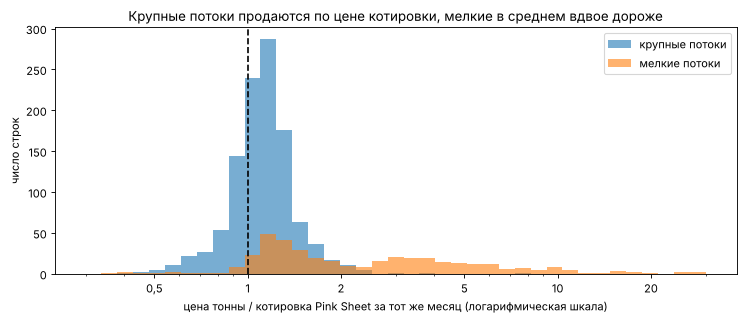

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
bins = np.logspace(np.log10(0.3), np.log10(30), 40)
ax.hist(big["ratio"], bins=bins, alpha=0.6, label="крупные потоки")
ax.hist(small["ratio"], bins=bins, alpha=0.6, label="мелкие потоки")
ax.axvline(1, color="black", linestyle="--")
ax.set_xscale("log")
ax.set_xticks([0.5, 1, 2, 5, 10, 20], ["0,5", "1", "2", "5", "10", "20"])
ax.set_xlabel("цена тонны / котировка Pink Sheet за тот же месяц (логарифмическая шкала)")
ax.set_ylabel("число строк")
ax.set_title("Крупные потоки продаются по цене котировки, мелкие в среднем вдвое дороже")
ax.legend()
plt.show()

In [5]:
print("Мелкие потоки по странам и направлению (X экспорт, M импорт):")
print(small.groupby(["country", "flowCode"]).size().to_string())
print()
print("Крупные потоки, которые дороже котировки в 2 раза и больше:")
big.loc[big["ratio"] > 2, ["country", "flowCode", "date", "tonnes", "usd_per_tonne", "ratio"]].round({"tonnes": 0, "usd_per_tonne": 0, "ratio": 2})

Мелкие потоки по странам и направлению (X экспорт, M импорт):
country            flowCode
Бразилия           X           51
Египет             M           60
Индия              X           75
Катар              M           17
Китай              M           67
Оман               M           65
Саудовская Аравия  M           65

Крупные потоки, которые дороже котировки в 2 раза и больше:


,country,flowCode,date,tonnes,usd_per_tonne,ratio
37,Египет,M,2015-04-01,16962.0,606.0,2.33
51,Оман,X,2015-05-01,63355.0,794.0,3.00
62,Оман,X,2015-06-01,24955.0,2266.0,7.85
276,США,X,2016-12-01,10082.0,462.0,2.12
333,Бразилия,X,2017-06-01,2604.0,396.0,2.07
364,Бразилия,X,2017-09-01,1472.0,531.0,2.42
400,Китай,M,2018-01-01,1327.0,491.0,2.24
425,США,X,2018-02-01,12875.0,470.0,2.02
728,США,X,2020-03-01,23098.0,479.0,2.07
1143,Индия,X,2023-02-01,28059.0,725.0,2.03


**Главный результат: крупные потоки продаются по цене, близкой к котировке, а мелкие в среднем вдвое дороже. Поэтому для анализа цен мы оставляем только потоки больше 1 000 тонн.**

- Минимальные и максимальные цены крупных и мелких потоков действительно пересекаются, но это ничего не говорит о типичной цене. Например, цена 771 доллар за тонну в 2022 году была обычной рыночной ценой, а в 2016 году она была почти вчетверо выше котировки.
- Если сравнивать каждую строку с котировкой того же месяца, разница очевидна. У крупных потоков медиана отношения цены к котировке равна 1,12, и половина строк лежит в узком диапазоне от 0,98 до 1,26. Небольшое превышение над котировкой частично объясняется тем, что цена импорта включает доставку. У мелких потоков медиана равна 2,03, а половина строк лежит в широком диапазоне от 1,28 до 4,28. Дороже котировки в 2 раза и больше половина мелких строк и только 1,5% крупных.
- Мелкие потоки почти всегда идут в обратную сторону: это импорт стран, которые сами экспортируют карбамид (Саудовская Аравия, Оман, Египет, Катар, Китай), и экспорт стран, которые карбамид импортируют (Индия, Бразилия). Удобрительный карбамид таким странам ввозить или вывозить незачем, поэтому в этих строках в основном специальный карбамид мелкими партиями: технический для промышленности, раствор для дизельных двигателей, очищенный для медицины и косметики. Такой товар стоит дороже удобрения.
- Среди крупных потоков 17 строк (1,5%) тоже дороже котировки в 2 раза и больше. В основном это экспорт Бразилии, США и Индии, то есть реэкспорт и специальный карбамид. Сюда же попали две строки экспорта Омана в мае и июне 2015 года (в 3 и почти в 8 раз дороже котировки, в июне 2 266 долларов за тонну), которые похожи на ошибку в стоимости или весе. Эти строки мы не удаляем, потому что главная проверка в разделе 1.3 опирается на экспорт Саудовской Аравии, где таких строк нет, и на выводы они не влияют.

### 1.3. Подтверждает ли Comtrade котировку Pink Sheet?
Мы сравниваем среднюю цену экспорта стран с ценой карбамида в Pink Sheet. В Pink Sheet начиная с марта 2022 года используется цена FOB Ближний Восток, а раньше использовалась цена FOB Чёрное море.

 страна (экспорт)  месяцев  корреляция с Pink Sheet  разница, медиана $/т
Саудовская Аравия      133                     0.95                    24
           Египет      138                     0.79                    46
             Оман       82                     0.59                   -22
            Китай      105                     0.88                    29
   Индия (импорт)      126                     0.87                    12
Бразилия (импорт)      126                     0.92                    29
     США (импорт)      128                     0.88                    31


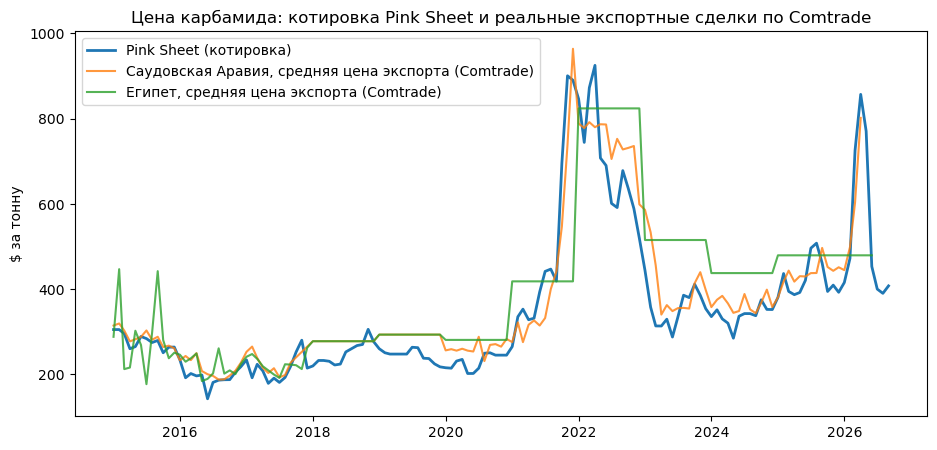

In [6]:
rows = []
for country in ["Саудовская Аравия", "Египет", "Оман", "Китай"]:
    s = big[(big["country"] == country) & (big["flowCode"] == "X")].set_index("date")["usd_per_tonne"]
    joined = pd.concat([s, pink], axis=1, join="inner").dropna()
    rows.append({"страна (экспорт)": country, "месяцев": len(joined),
                 "корреляция с Pink Sheet": round(joined.corr().iloc[0, 1], 2),
                 "разница, медиана $/т": round((joined.iloc[:, 0] - joined.iloc[:, 1]).median())})
for country in ["Индия", "Бразилия", "США"]:
    s = big[(big["country"] == country) & (big["flowCode"] == "M")].set_index("date")["usd_per_tonne"]
    joined = pd.concat([s, pink], axis=1, join="inner").dropna()
    rows.append({"страна (экспорт)": country + " (импорт)", "месяцев": len(joined),
                 "корреляция с Pink Sheet": round(joined.corr().iloc[0, 1], 2),
                 "разница, медиана $/т": round((joined.iloc[:, 0] - joined.iloc[:, 1]).median())})
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(pink.loc["2015":].index, pink.loc["2015":], label="Pink Sheet (котировка)", linewidth=2)
for country in ["Саудовская Аравия", "Египет"]:
    s = big[(big["country"] == country) & (big["flowCode"] == "X")].set_index("date")["usd_per_tonne"]
    ax.plot(s.index, s, label=f"{country}, средняя цена экспорта (Comtrade)", alpha=0.8)
ax.set_ylabel("$ за тонну")
ax.set_title("Цена карбамида: котировка Pink Sheet и реальные экспортные сделки по Comtrade")
ax.legend()
plt.show()

**Главный результат: котировка Pink Sheet отражает цены реальных сделок, и лучше всего это видно на Саудовской Аравии, одном из крупнейших экспортёров карбамида в мире.**

Саудовская Аравия вывозит около 4,3 миллиона тонн карбамида в год (раздел 2.3б). Среди стран, которые публикуют помесячные данные в Comtrade, она является крупнейшим стабильным экспортёром (раздел 1.5). Кроме того, она отгружает карбамид из портов Персидского залива, а с марта 2022 года котировка Pink Sheet считается именно как цена FOB Ближний Восток. Поэтому цена саудовского экспорта является самой подходящей проверкой нашей целевой цены.

Средняя цена экспорта карбамида из Саудовской Аравии почти совпадает с котировкой Pink Sheet: корреляция составляет около 0,95, а разница составляет около 24 долларов за тонну. Значит, наша целевая цена отражает реальную торговлю, а не только оценку ценового агентства.

У Египта связь слабее (корреляция 0,79), у Омана ещё слабее (0,59). На графике видно, что у Египта, а в некоторые годы и у Саудовской Аравии, цена месяцами стоит на одном уровне. Скорее всего, в эти годы страна передала в Comtrade одну среднюю цену сразу за весь год, поэтому помесячного движения цены в данных нет. У Омана в данных есть пропуски и единичные подозрительные значения (например, экспорт в июне 2015 года по 2 266 долларов за тонну), а в его экспорт могут входить контракты с другими сроками.

### 1.4. Ограничения экспорта Китая в цифрах
Китай является одним из крупнейших экспортёров карбамида и производит его в основном из угля. С осени 2021 года Китай вводил инспекции и квоты на экспорт удобрений.

Экспорт карбамида из Китая, медиана, тыс. т в месяц:
2016–2020              363.0
янв–сен 2021           355.0
ноя 2021 – дек 2022    169.0
2023                   277.0
2024                     8.0


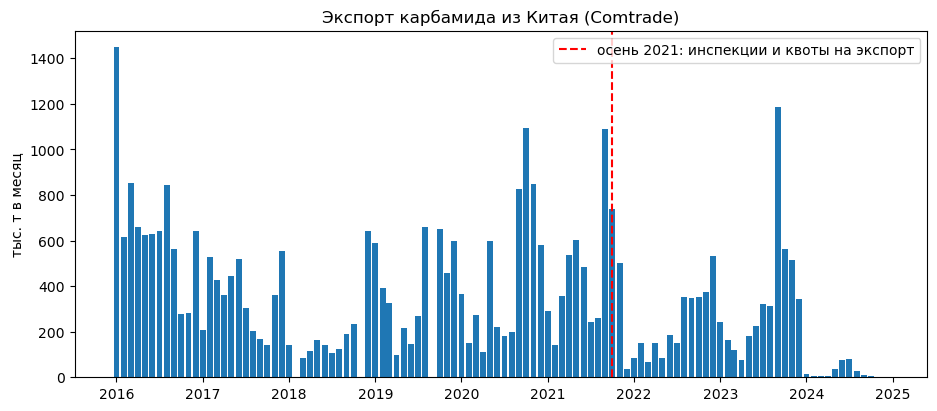

In [7]:
china = big[(big["country"] == "Китай") & (big["flowCode"] == "X")].set_index("date")["tonnes"] / 1000
summary = pd.Series({
    "2016–2020": china.loc["2016":"2020"].median(),
    "янв–сен 2021": china.loc["2021-01":"2021-09"].median(),
    "ноя 2021 – дек 2022": china.loc["2021-11":"2022-12"].median(),
    "2023": china.loc["2023"].median(),
    "2024": china.loc["2024"].median(),
}).round()
print("Экспорт карбамида из Китая, медиана, тыс. т в месяц:")
print(summary.to_string())

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(china.index, china, width=25)
ax.axvline(pd.Timestamp("2021-10-01"), color="red", linestyle="--", label="осень 2021: инспекции и квоты на экспорт")
ax.set_ylabel("тыс. т в месяц")
ax.set_title("Экспорт карбамида из Китая (Comtrade)")
ax.legend()
plt.show()

**Главный результат: после ограничений экспорт карбамида из Китая упал примерно вдвое, а в 2024 году почти остановился.**

В период с 2016 по 2020 год медианный экспорт составлял 363 тысячи тонн в месяц. В период с ноября 2021 по декабрь 2022 года медиана упала до 169 тысяч тонн. В 2023 году экспорт частично восстановился до 277 тысяч тонн, а в 2024 году медиана составила всего 8 тысяч тонн в месяц. Эти данные служат проверкой для признака china_export_restr, то есть ручной разметки ограничений: даты в разметке должны совпадать с провалами экспорта. Сами объёмы из Comtrade как признак не подходят, потому что данные по Китаю заканчиваются декабрём 2024 года.

### 1.5. Кто экспортирует: вес Ближнего Востока
Мы сравниваем средний месячный экспорт крупнейших стран, которые публикуют данные.

Средний экспорт, тыс. т в месяц, 2019–2023:
country
Китай                376.0
Саудовская Аравия    345.0
Египет               298.0
Оман                 235.0


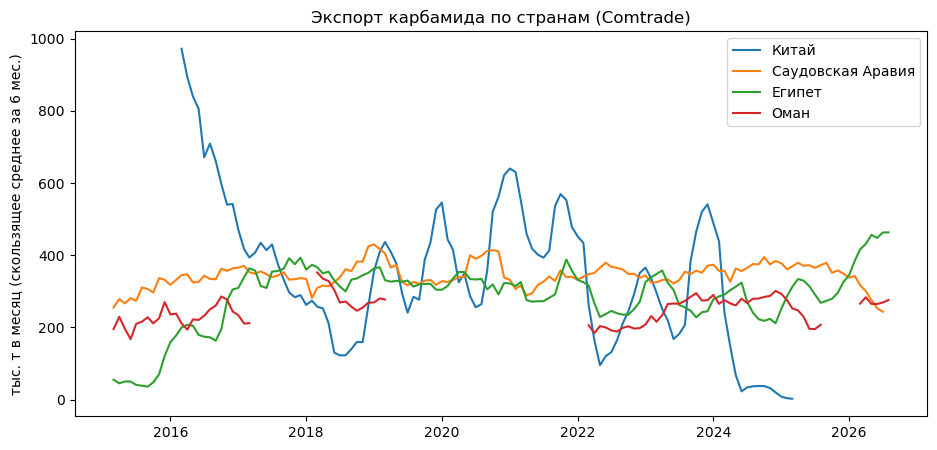

In [8]:
exports = big[big["flowCode"] == "X"].pivot_table(index="date", columns="country", values="tonnes") / 1000
main = ["Китай", "Саудовская Аравия", "Египет", "Оман"]
print("Средний экспорт, тыс. т в месяц, 2019–2023:")
print(exports.loc["2019":"2023", main].mean().round().sort_values(ascending=False).to_string())

fig, ax = plt.subplots(figsize=(11, 5))
for country in main:
    ax.plot(exports.index, exports[country].rolling(6, min_periods=3).mean(), label=country)
ax.set_ylabel("тыс. т в месяц (скользящее среднее за 6 мес.)")
ax.set_title("Экспорт карбамида по странам (Comtrade)")
ax.legend()
plt.show()

**Главный результат: среди стран, которые публикуют данные, крупнейшим стабильным экспортёром является Саудовская Аравия, и она отгружает карбамид через Ормузский пролив.**

В период с 2019 по 2023 год Саудовская Аравия экспортировала в среднем около 345 тысяч тонн в месяц. Китай в среднем экспортировал больше (376 тысяч тонн), но его экспорт нестабилен вследствие ограничений. Саудовская Аравия отгружает карбамид через порты Персидского залива, то есть через Ормузский пролив. Это аргумент в пользу признаков трафика через Ормузский пролив по данным PortWatch. Катар тоже является крупным экспортёром и тоже отгружает через Ормузский пролив, но его помесячного экспорта в Comtrade нет. Оман отгружает карбамид из портов, которые находятся за пределами пролива.

### 1.6. Стоимость доставки: разница CIF и FOB
Бразилия и США указывают стоимость импорта в двух вариантах: на условиях CIF, то есть с фрахтом и страховкой, и на условиях FOB, то есть без них. Разница между ними в расчёте на тонну даёт прямую оценку стоимости доставки до покупателя.

Фрахт и страховка (CIF − FOB), медиана по годам, $/т:
      Бразилия   США
date                
2015      19.0   NaN
2016      14.0  17.0
2017      17.0  18.0
2018      21.0  22.0
2019      20.0  22.0
2020      18.0  20.0
2021      28.0   NaN
2022      45.0  43.0
2023      29.0  24.0
2024      31.0  24.0
2025      27.0  25.0
2026      33.0  25.0


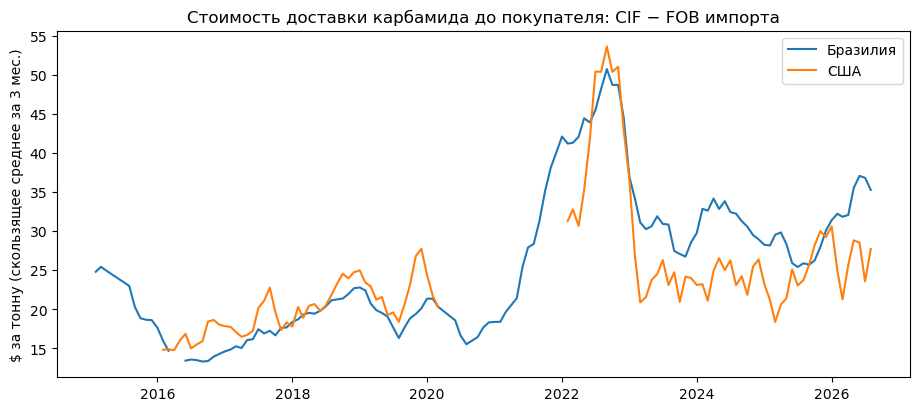

In [9]:
freight = {}
for country in ["Бразилия", "США"]:
    s = trade[(trade["country"] == country) & (trade["flowCode"] == "M") & (trade["fobvalue"] > 0) & (trade["tonnes"] > 1000)].set_index("date")
    freight[country] = (s["cifvalue"] - s["fobvalue"]) / s["tonnes"]
freight = pd.DataFrame(freight)
print("Фрахт и страховка (CIF − FOB), медиана по годам, $/т:")
print(freight.groupby(freight.index.year).median().round().to_string())

fig, ax = plt.subplots(figsize=(11, 4.5))
for country in freight:
    ax.plot(freight.index, freight[country].rolling(3, min_periods=2).mean(), label=country)
ax.set_ylabel("$ за тонну (скользящее среднее за 3 мес.)")
ax.set_title("Стоимость доставки карбамида до покупателя: CIF − FOB импорта")
ax.legend()
plt.show()

**Главный результат: доставка в спокойные годы стоит от 15 до 22 долларов за тонну, а в 2022 году стоила около 45 долларов.**

В 2022 году доставка подорожала вследствие кризиса фрахта и логистики. После 2022 года стоимость доставки составляет от 24 до 33 долларов за тонну. Это готовая составляющая надбавки «транспортные расходы», которую разбирает Стёпа. Ряд по месяцам есть с 2015 года для Бразилии и с 2016 года для США. Задержка публикации у этих стран небольшая, один месяц, поэтому этот ряд можно пробовать как признак с запаздыванием в 1 или 2 месяца.

### 1.7. Итог: чем Comtrade полезен проекту

| Что даёт | Как используем |
|---|---|
| Средние цены реальных сделок | проверили, что котировка Pink Sheet совпадает с ценой экспорта Саудовской Аравии (корреляция 0,95) |
| Экспорт Китая | проверяем разметку china_export_restr; видно падение с осени 2021 года и почти полную остановку в 2024 году |
| Объёмы экспорта по странам | оцениваем вес Ормузского пролива: крупнейший публикующий экспортёр (Саудовская Аравия) отгружает через пролив |
| Разница CIF и FOB импорта Бразилии и США | получаем составляющую надбавки «доставка»: от 15 до 22 долларов за тонну в спокойные годы, около 45 долларов в 2022 году |
| Ограничения | задержка публикации от 1 до 5 месяцев (по Китаю нет данных с 2025 года), Катар и Россия не публикуют помесячный экспорт; поэтому как признак в реальном времени данные не годятся, только с запаздыванием |

## 2. Оборотный капитал, ставки и валютные курсы

**Задача.** Разложить надбавку на составляющие и оценить одну из них: затраты на оборотный капитал. Оборотный капитал показывает, сколько денег «заморожено», пока товар производится, хранится, плывёт к покупателю и ждёт оплаты. Затраты на него равны стоимости кредита на это время, причём в некоторых странах кредиты заметно дороже. Дополнительно мы проверяем влияние валютных курсов.

затраты на тонну = цена тонны × дни цикла × ставка / 365

затраты в год = стоимость груза × число судов в год × дни цикла × ставка / 365

**Данные.**
- Дни цикла взяты из квартальной отчётности SEC (база EDGAR) трёх производителей азотных удобрений в США: CF Industries, CVR Partners и LSB Industries (скрипт src/data/load_edgar.py).
- Ставки и валютные курсы взяты из базы FRED (скрипт src/data/load_fred.py).
- Цена карбамида взята из Pink Sheet.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

wc = pd.read_csv("../data/processed/working_capital_quarterly.csv", parse_dates=["quarter_end"])
fred = pd.read_csv("../data/processed/fred_monthly.csv", index_col="date", parse_dates=True)
prices = pd.read_parquet("../data/processed/prices_monthly.parquet").loc["2015-04":]
print("Оборотный капитал:", len(wc), "компания-кварталов,", wc["quarter_end"].min().date(), "–", wc["quarter_end"].max().date())
print("FRED:", fred.index.min().date(), "–", fred.index.max().date(), list(fred.columns))

Оборотный капитал: 153 компания-кварталов, 2014-03-31 – 2026-09-30
FRED: 2010-01-01 – 2026-11-01 ['fed_rate', 'sofr', 'spread_us_bbb', 'spread_em_corp', 'usd_index', 'inr_per_usd', 'brl_per_usd']


### 2.1. Дни цикла по отчётности производителей

- **DSO** показывает, через сколько дней покупатель оплачивает товар: DSO = дебиторская задолженность / выручка за квартал × 91.
- **DIO** показывает, сколько дней товар хранится на складе: DIO = запасы / себестоимость за квартал × 91.
- **DPO** показывает, на сколько дней производитель откладывает оплату поставщикам, в том числе за газ: DPO = кредиторская задолженность / себестоимость за квартал × 91.
- **DSO + DIO** показывает, сколько дней деньги вложены в товар (валовой цикл). **DSO + DIO − DPO** показывает, сколько из этих дней производитель финансирует сам.

Медианы по кварталам 2014–2026, дней:
                 DSO   DIO   DPO  DSO + DIO  цикл (− DPO)
company                                                  
CF Industries   23.6  32.3  52.7       57.3           6.7
CVR Partners    25.2  64.6  27.4       86.1          55.3
LSB Industries  42.8  19.3  50.0       61.8          11.8

Пропуски по колонкам, %:
revenue        8.5
cogs           3.3
receivables    0.0
inventory      0.7
payables       9.8


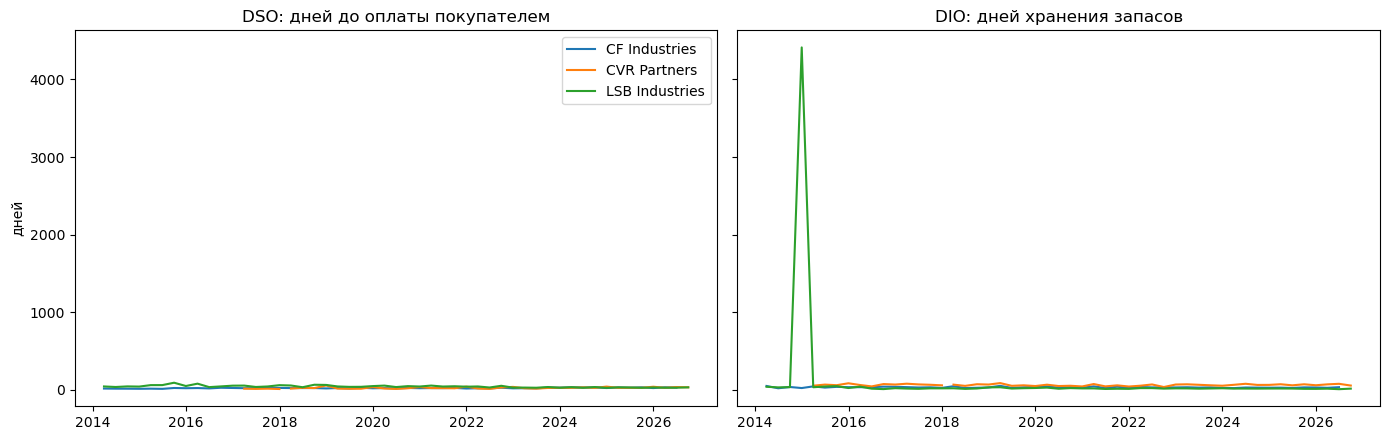

In [11]:
wc["gross_days"] = wc["dso_days"] + wc["dio_days"]
summary = wc.groupby("company")[["dso_days", "dio_days", "dpo_days", "gross_days", "cycle_days"]].median().round(1)
summary.columns = ["DSO", "DIO", "DPO", "DSO + DIO", "цикл (− DPO)"]
print("Медианы по кварталам 2014–2026, дней:")
print(summary.to_string())

print("\nПропуски по колонкам, %:")
print((wc[["revenue", "cogs", "receivables", "inventory", "payables"]].isna().mean() * 100).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for company, part in wc.groupby("company"):
    part = part.sort_values("quarter_end")
    axes[0].plot(part["quarter_end"], part["dso_days"], label=company)
    axes[1].plot(part["quarter_end"], part["dio_days"], label=company)
axes[0].set_title("DSO: дней до оплаты покупателем")
axes[1].set_title("DIO: дней хранения запасов")
axes[0].set_ylabel("дней")
axes[0].legend()
plt.tight_layout()
plt.show()

**Главный результат: деньги производителя вложены в товар в среднем около 60 дней.**

- Сумма DSO и DIO составляет у CF Industries около 57 дней, у LSB Industries около 62 дней, у CVR Partners около 86 дней. Из этого срока от 20 до 45 дней приходится на ожидание оплаты от покупателей, а от 20 до 65 дней продукция лежит на складе, потому что производители копят запасы к сезону внесения удобрений.
- Показатель DPO у CF Industries завышен. Компания отчитывается в основном строкой «кредиторская задолженность и начисленные обязательства», поэтому цикл за вычетом DPO у неё получается почти нулевым. Поэтому для расчёта затрат мы берём сумму DSO и DIO: именно столько дней деньги заморожены в товаре.
- Это американские производители, которые продают удобрения в основном внутри страны. У экспортёров Ближнего Востока к циклу добавляется морской рейс: около 10 дней до Индии и около 30 дней до Бразилии. Эти сроки мы уточним по данным PortWatch, которые собирает Саша.
- У CF Industries в отчётности есть отдельная строка «задолженность за покупку газа». Это означает, что газ оплачивается с отсрочкой, и потребность компании в оборотном капитале снижается.

### 2.2. Ставка по кредиту
Ставка ФРС служит базой для кредитов в долларах. Спреды корпоративных облигаций показывают, сколько компания платит сверх базовой ставки. FRED отдаёт спреды только за последние 3 года вследствие ограничения лицензии ICE. Поэтому мы используем спреды, чтобы обосновать надбавку банка, а не как ряд с 2015 года.

In [12]:
print("Спреды с ноября 2023, медиана, п.п.:")
print(fred[["spread_us_bbb", "spread_em_corp"]].dropna().median().round(2).to_string())

BANK_SPREAD = 2.0
fred["financing_rate"] = fred["fed_rate"] + BANK_SPREAD
print(f"\nСтавка = ставка ФРС + {BANK_SPREAD} п.п. Средняя по годам, %:")
print(fred["financing_rate"].loc["2015":].groupby(fred.loc["2015":].index.year).mean().round(2).to_string())

Спреды с ноября 2023, медиана, п.п.:
spread_us_bbb     1.07
spread_em_corp    1.69

Ставка = ставка ФРС + 2.0 п.п. Средняя по годам, %:
date
2015    2.13
2016    2.40
2017    3.00
2018    3.83
2019    4.16
2020    2.38
2021    2.08
2022    3.68
2023    7.02
2024    7.14
2025    6.21
2026    5.67


**Главный результат: для расчёта затрат мы берём ставку ФРС плюс надбавку банка в 2 процентных пункта.**

Компании США с рейтингом BBB платят сверх базовой ставки около 1 процентного пункта, а компании развивающихся стран около 1,7 процентного пункта. Это данные по облигациям, а банковский кредит обычно дороже, поэтому мы берём надбавку в 2 процентных пункта. В период с 2015 по 2026 год итоговая ставка менялась примерно от 2% (в 2015 году, а также в 2020 и 2021 годах) примерно до 7% (в 2023 и 2024 годах). Изменение ставки является главной причиной того, что затраты на финансирование меняются во времени.

### 2.3. Затраты на финансирование в долларах на тонну по месяцам

Дни цикла: 62 (DSO + DIO, медиана по компаниям) + 10 (рейс до Индии) = 72
count    138.0
mean       3.0
std        2.0
min        0.7
25%        1.2
50%        2.1
75%        4.7
max        9.5

Доля в надбавке (k = 12), медиана: 1.0 %
Затраты по годам, $/т:
date
2015    1.1
2016    0.9
2017    1.3
2018    1.9
2019    2.0
2020    1.1
2021    2.0
2022    4.8
2023    4.9
2024    4.7
2025    5.2
2026    6.0

Затраты в год (2026-09): груз 40,000 т × 50 судов × 72 дн. × 5.75% = $9.2 млн в год


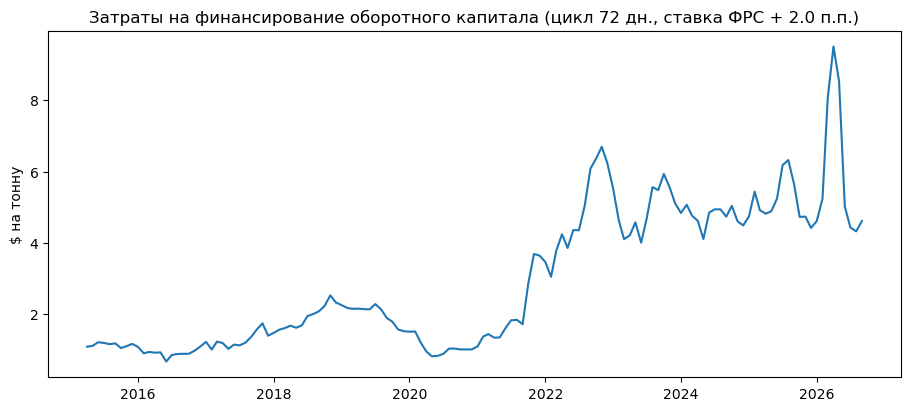

In [13]:
gross_days = wc.groupby("company")["gross_days"].median().median()
VOYAGE_DAYS = 10
cycle_days = gross_days + VOYAGE_DAYS
print(f"Дни цикла: {gross_days:.0f} (DSO + DIO, медиана по компаниям) + {VOYAGE_DAYS} (рейс до Индии) = {cycle_days:.0f}")

df = prices.join(fred[["financing_rate"]])
df["financing_cost_usd_t"] = df["urea_price"] * cycle_days * df["financing_rate"] / 100 / 365
df["markup_k12"] = df["urea_price"] - 12 * df["gas_europe"]
df["share_of_markup_%"] = df["financing_cost_usd_t"] / df["markup_k12"] * 100

print(df["financing_cost_usd_t"].describe().round(1).to_string())
print("\nДоля в надбавке (k = 12), медиана:", round(df["share_of_markup_%"].median(), 1), "%")
print("Затраты по годам, $/т:")
print(df["financing_cost_usd_t"].groupby(df.index.year).mean().round(1).to_string())

latest = df.dropna().iloc[-1]
cargo_tonnes, ships_per_year = 40000, 50
annual = latest["urea_price"] * cargo_tonnes * ships_per_year * cycle_days * latest["financing_rate"] / 100 / 365
print(f"\nЗатраты в год ({latest.name:%Y-%m}): груз {cargo_tonnes:,} т × {ships_per_year} судов × {cycle_days:.0f} дн. × {latest['financing_rate']:.2f}% = ${annual / 1e6:.1f} млн в год")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(df.index, df["financing_cost_usd_t"])
ax.set_ylabel("$ на тонну")
ax.set_title(f"Затраты на финансирование оборотного капитала (цикл {cycle_days:.0f} дн., ставка ФРС + {BANK_SPREAD} п.п.)")
plt.show()

**Главный результат: затраты на финансирование оборотного капитала составляют несколько долларов на тонну, то есть около 1% надбавки.**

При цикле около 72 дней затраты составляли от 1 до 2 долларов на тонну в период с 2015 по 2021 год и от 5 до 6 долларов в период с 2022 по 2026 год. Рост объясняется более высокими ценами на карбамид и более высокими ставками. Медианная доля затрат в надбавке составляет около 1%. Эта составляющая небольшая, но она меняется по понятным причинам: вследствие ставки ФРС, цены груза и длины рейса (например, при обходе Красного моря или при перекрытии Ормузского пролива). В модели её можно использовать как признак financing_cost_usd_t. При ставке 20%, как в странах с дорогими кредитами, и цикле 120 дней затраты составили бы около 27 долларов на тонну, то есть примерно в 4,5 раза больше нынешних 6 долларов.

In [14]:
price_now = latest["urea_price"]
sens = pd.DataFrame(
    {f"ставка {r}%": [round(price_now * d * r / 100 / 365, 1) for d in [60, 90, 120]] for r in [5, 8, 20]},
    index=["60 дней", "90 дней", "120 дней"],
)
print(f"Чувствительность при цене ${price_now:.0f}/т ({latest.name:%Y-%m}), $ на тонну:")
sens

Чувствительность при цене $408/т (2026-09), $ на тонну:


,ставка 5%,ставка 8%,ставка 20%
60 дней,3.3,5.4,13.4
90 дней,5.0,8.0,20.1
120 дней,6.7,10.7,26.8


### 2.3а. Дорогие кредиты в странах, где производят карбамид
В некоторых странах кредиты заметно дороже, чем в долларах. Мы берём ключевые ставки центральных банков из базы BIS (скрипт src/data/load_bis_rates.py) и считаем затраты на финансирование при местной ставке плюс 2 процентных пункта. Египта в базе BIS нет.

Ключевые ставки 2015–2026, %:
     rate_india  rate_china  rate_russia  rate_saudi_arabia  rate_brazil
min        4.00        3.00         4.25               1.00         2.00
50%        6.00        3.85         9.50               2.25        11.75
max        7.75        5.60        21.00               6.00        15.00

Затраты на финансирование при местной ставке + 2 п.п., $ на тонну, средние по годам:
      cost_rate_india  cost_rate_china  cost_rate_russia  cost_rate_saudi_arabia  cost_rate_brazil  cost_usd_fed
date                                                                                                            
2015              4.8              3.6               7.2                     2.1               8.5           1.1
2016              3.2              2.4               4.8                     1.5               6.2           0.9
2017              3.4              2.7               4.6                     1.7               5.0           1.3
2018              4.1      

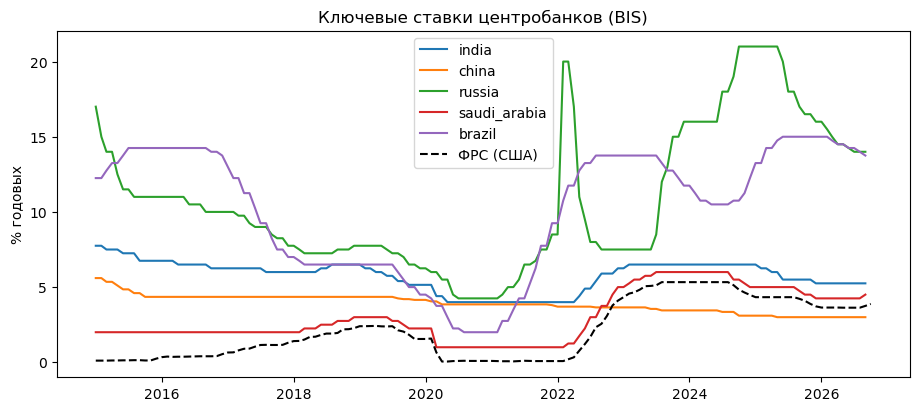

In [15]:
policy = pd.read_csv("../data/processed/policy_rates_monthly.csv", index_col="date", parse_dates=True)
print("Ключевые ставки 2015–2026, %:")
print(policy.loc["2015":].describe().loc[["min", "50%", "max"]].round(2).to_string())

local = prices[["urea_price"]].join(policy)
for col in policy.columns:
    local["cost_" + col] = local["urea_price"] * cycle_days * (local[col] + BANK_SPREAD) / 100 / 365
local["cost_usd_fed"] = df["financing_cost_usd_t"]
cost_cols = [c for c in local.columns if c.startswith("cost_")]
print("\nЗатраты на финансирование при местной ставке + 2 п.п., $ на тонну, средние по годам:")
print(local[cost_cols].groupby(local.index.year).mean().round(1).to_string())

fig, ax = plt.subplots(figsize=(11, 4.5))
for col in policy.columns:
    ax.plot(policy.loc["2015":].index, policy.loc["2015":, col], label=col.replace("rate_", ""))
ax.plot(fred.loc["2015":].index, fred.loc["2015":, "fed_rate"], color="black", linestyle="--", label="ФРС (США)")
ax.set_ylabel("% годовых")
ax.set_title("Ключевые ставки центробанков (BIS)")
ax.legend()
plt.show()

**Главный результат: при местных ставках в России и Бразилии финансирование того же груза обходится в несколько раз дороже, чем при долларовой ставке.**

Ставка Саудовской Аравии привязана к ставке ФРС, потому что риал привязан к доллару. Поэтому затраты саудовских экспортёров такие же, как в долларовом расчёте выше. В России ключевая ставка доходила до 21%, в Бразилии до 15%. Если производитель берёт кредит в местной валюте, финансирование груза обходится примерно от 10 до 20 долларов на тонну, тогда как при долларовой ставке оно обходится от 2 до 6 долларов. На мировую цену это влияет мало, потому что её задаёт самый дорогой производитель, который ещё нужен рынку, а не самый закредитованный. Однако это объясняет, почему у разных экспортёров разная маржа.

### 2.3б. Уточнения: предоплаты, сумма оборотного капитала, реальная ставка, число судов, доля в марже

Сначала мы чистим ошибочные значения. В отдельных кварталах выручка или себестоимость, восстановленные из нарастающего итога, получаются почти нулевыми, и тогда число дней взлетает до тысяч. Процентная ставка по долгу бывает отрицательной, когда компании возвращают проценты, или бесконечной, когда долг погашен. Такие значения мы считаем ошибками и убираем.

In [16]:
clean = wc.copy()
bad = pd.DataFrame({
    "DIO > 200 дней": clean["dio_days"] > 200,
    "DPO > 200 дней": clean["dpo_days"] > 200,
    "ставка по долгу вне 0–20%": ~clean["debt_rate_pct"].between(0, 20) & clean["debt_rate_pct"].notna(),
})
print("Найдено ошибочных значений:")
print(bad.sum().to_string())
clean.loc[bad["DIO > 200 дней"], "dio_days"] = np.nan
clean.loc[bad["DPO > 200 дней"], "dpo_days"] = np.nan
clean.loc[bad["ставка по долгу вне 0–20%"], "debt_rate_pct"] = np.nan
clean["year"] = clean["quarter_end"].dt.year

Найдено ошибочных значений:
DIO > 200 дней               1
DPO > 200 дней               1
ставка по долгу вне 0–20%    7


#### Предоплата покупателей
Фермеры и дистрибьюторы часто платят вперёд, то есть до отгрузки. В отчётности такие суммы отражаются как «обязательства по договорам с покупателями» или как «отложенная выручка». Пока аванс находится у производителя, ему нужно меньше собственных денег.

In [17]:
print("Авансы покупателей, дней выручки (медиана по годам):")
print(clean.pivot_table(index="year", columns="company", values="advance_days", aggfunc="median").round(1).to_string())

clean["net_days"] = clean["dso_days"] + clean["dio_days"] - clean["advance_days"].fillna(0)
net_days = clean.groupby("company")["net_days"].median().median()
print(f"\nДни, которые производитель финансирует сам: DSO + DIO − авансы = {net_days:.0f} (медиана по компаниям; было {gross_days:.0f} без учёта авансов)")

Авансы покупателей, дней выручки (медиана по годам):
company  CF Industries  CVR Partners  LSB Industries
year                                                
2017               NaN          15.0             8.5
2018               NaN          31.8             6.4
2019              10.3          23.2             4.5
2020              13.0          22.1             2.6
2021              25.1          31.6             1.0
2022              13.5          26.7             0.7
2023              10.2          14.1             0.6
2024               6.7          21.4             0.7
2025               8.5          18.0             0.6
2026               3.2          14.3             0.3

Дни, которые производитель финансирует сам: DSO + DIO − авансы = 56 (медиана по компаниям; было 62 без учёта авансов)


#### Сколько денег вложено в оборотный капитал
Оборотный капитал = дебиторская задолженность + запасы − кредиторская задолженность − авансы покупателей.

In [18]:
clean["annual_revenue"] = clean.groupby("company")["revenue"].transform(lambda s: s.rolling(4, min_periods=4).sum())
clean["wc_share_pct"] = clean["working_capital_usd"] / clean["annual_revenue"] * 100
table = clean.groupby("company").agg(
    оборотный_капитал_млн=("working_capital_usd", lambda s: s.median() / 1e6),
    доля_годовой_выручки_pct=("wc_share_pct", "median"),
).round(1)
print(table.to_string())

                оборотный_капитал_млн  доля_годовой_выручки_pct
company                                                        
CF Industries                    -1.0                      -0.0
CVR Partners                     30.2                       8.3
LSB Industries                   17.2                       3.4


#### Реальная ставка, по которой занимают производители
Реальная ставка = процентные расходы за квартал × 4 / долг. Мы сравниваем её с допущением «ставка ФРС плюс 2 процентных пункта».

In [19]:
real_rate = clean.pivot_table(index="year", columns="company", values="debt_rate_pct", aggfunc="median")
real_rate["ставка ФРС + 2 п.п."] = fred["financing_rate"].groupby(fred.index.year).mean()
print("Ставка, % годовых:")
print(real_rate.loc[2015:].round(1).to_string())
REAL_RATE = clean["debt_rate_pct"].median()
print(f"\nМедиана реальной ставки по трём компаниям: {REAL_RATE:.1f}%")

Ставка, % годовых:
company  CF Industries  CVR Partners  LSB Industries  ставка ФРС + 2 п.п.
year                                                                     
2015               2.7           4.8             1.4                  2.1
2016               3.6           4.9             7.3                  2.4
2017               6.4           9.6             9.3                  3.0
2018               5.2           9.6            10.8                  3.8
2019               5.6           9.5            10.7                  4.2
2020               4.6           9.4             0.1                  2.4
2021               5.1           6.5            10.7                  2.1
2022               8.6           6.6             7.0                  3.7
2023               5.1           6.2             6.9                  7.0
2024               5.0           6.0             6.9                  7.1
2025               5.0           6.5             6.7                  6.2
2026               

#### Число судов в год по данным Comtrade

In [20]:
trade = pd.read_csv("../data/raw/comtrade_urea_monthly.csv", parse_dates=["date"])
CARGO_TONNES = 40000
exports = trade[(trade["flowCode"] == "X") & (trade["country"].isin(["Саудовская Аравия", "Египет", "Оман"]))]
yearly = exports.groupby(["country", exports["date"].dt.year])["tonnes"].sum().unstack(0) / 1e6
ships = (yearly * 1e6 / CARGO_TONNES).round()
print("Экспорт карбамида, млн т в год:")
print(yearly.loc[2019:2025].round(2).to_string())
print(f"\nЧисло судов в год (партия {CARGO_TONNES:,} т):")
print(ships.loc[2019:2025].to_string())

Экспорт карбамида, млн т в год:
country  Египет  Оман  Саудовская Аравия
date                                    
2019       3.79   NaN               3.87
2020       3.94   NaN               4.43
2021       3.78   NaN               3.95
2022       3.05  2.39               4.30
2023       3.29  3.25               4.16
2024       3.22  3.49               4.44
2025       3.84  0.98               4.33

Число судов в год (партия 40,000 т):
country  Египет  Оман  Саудовская Аравия
date                                    
2019       95.0   NaN               97.0
2020       99.0   NaN              111.0
2021       95.0   NaN               99.0
2022       76.0  60.0              107.0
2023       82.0  81.0              104.0
2024       80.0  87.0              111.0
2025       96.0  25.0              108.0


In [21]:
year = 2025
saudi_ships = ships.loc[year, "Саудовская Аравия"]
saudi_price = exports[(exports["country"] == "Саудовская Аравия") & (exports["date"].dt.year == year)]
saudi_price = saudi_price["primaryValue"].sum() / saudi_price["tonnes"].sum()
days = net_days + VOYAGE_DAYS
cost = saudi_price * CARGO_TONNES * saudi_ships * days * REAL_RATE / 100 / 365
print(f"Затраты в год, Саудовская Аравия, {year}:")
print(f"  стоимость груза ${saudi_price:,.0f}/т × {CARGO_TONNES:,} т = ${saudi_price * CARGO_TONNES / 1e6:.1f} млн")
print(f"  × {saudi_ships:.0f} судов × {days:.0f} дней × {REAL_RATE:.1f}% / 365")
print(f"  = ${cost / 1e6:.1f} млн в год, или ${cost / (CARGO_TONNES * saudi_ships):.1f} на тонну")

Затраты в год, Саудовская Аравия, 2025:
  стоимость груза $437/т × 40,000 т = $17.5 млн
  × 108 судов × 66 дней × 5.2% / 365
  = $17.7 млн в год, или $4.1 на тонну


#### Связь с прибыльностью завода: какую долю валовой маржи съедают затраты на финансирование
Доля в марже = затраты на финансирование на тонну / валовая маржа на тонну = (дни × ставка / 365) / маржа в процентах.

Финансирование = 0.94% цены тонны

Валовая маржа, %:
company  CF Industries  CVR Partners  LSB Industries
year                                                
2015              34.4           NaN            -7.5
2016              16.2           NaN            -8.3
2017              11.7           4.7             0.7
2018              20.6           8.9             6.5
2019              22.0           9.7            -2.6
2020              18.7           2.7             0.8
2021              32.0          31.9            19.3
2022              53.5          51.3            42.6
2023              37.4          28.9            15.4
2024              33.4          22.6            10.3
2025              39.0          31.1            15.9
2026              44.5          37.5            21.1

Доля финансирования в валовой марже, %:
company  CF Industries  CVR Partners  LSB Industries
year                                                
2015               2.7           NaN             NaN
2016 

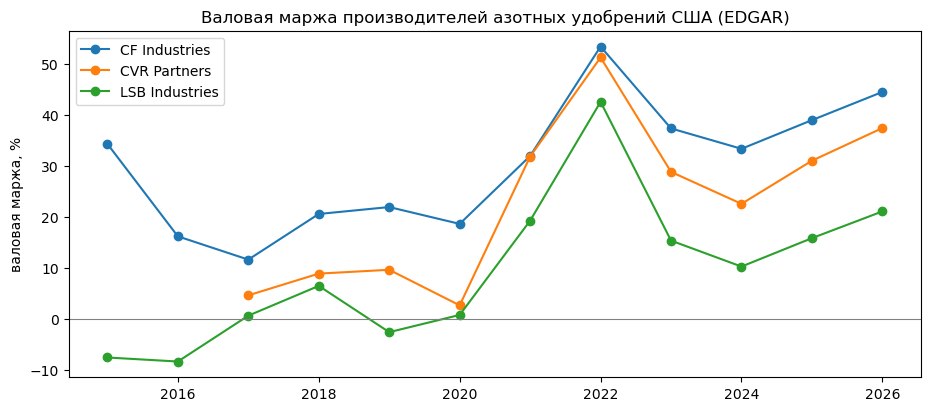

In [22]:
margin = clean.pivot_table(index="year", columns="company", values="gross_margin_pct", aggfunc="median")
financing_share_of_price = (net_days + VOYAGE_DAYS) * REAL_RATE / 365
share_of_margin = (financing_share_of_price / margin * 100).where(margin > 2)
print(f"Финансирование = {financing_share_of_price:.2f}% цены тонны")
print("\nВаловая маржа, %:")
print(margin.loc[2015:].round(1).to_string())
print("\nДоля финансирования в валовой марже, %:")
print(share_of_margin.loc[2015:].round(1).to_string())

fig, ax = plt.subplots(figsize=(11, 4.5))
for company in margin.columns:
    ax.plot(margin.loc[2015:].index, margin.loc[2015:, company], marker="o", label=company)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_ylabel("валовая маржа, %")
ax.set_title("Валовая маржа производителей азотных удобрений США (EDGAR)")
ax.legend()
plt.show()

**Главный результат уточнений: затраты на финансирование составляют около 1% цены тонны и почти не влияют на цену, но в слабые годы съедают заметную часть маржи небольших производителей.**

- **Ошибочные значения.** Мы нашли и убрали 1 квартал с DIO больше 200 дней, 1 квартал с DPO больше 200 дней и 7 кварталов с нереальной ставкой по долгу, то есть отрицательной или бесконечной.
- **Предоплата заметна.** Авансы покупателей покрывают от 10 до 30 дней выручки у CF Industries и CVR Partners, а у LSB Industries только 1 или 2 дня. В 2021 году, в разгар дефицита, авансы выросли (у CF Industries до 25 дней), потому что покупатели спешили закрепить за собой объёмы. С учётом авансов производитель сам финансирует около 56 дней, а не 62 дня.
- **Сумма оборотного капитала.** У CVR Partners она составляет около 30 миллионов долларов, это около 8% годовой выручки. У LSB Industries около 17 миллионов долларов, это около 3% выручки. У CF Industries оборотный капитал около нуля, потому что её кредиторская задолженность включает начисленные обязательства, а авансы покупателей велики.
- **Реальная ставка.** Производители занимают в среднем под ставку от 5 до 7% (медиана 5,2%), потому что их долг в основном состоит из облигаций с фиксированной ставкой. В период с 2015 по 2021 год реальная ставка была заметно выше допущения «ставка ФРС плюс 2 процентных пункта», которое давало от 2 до 4%. В 2023 и 2024 годах реальная ставка была ниже допущения, которое давало около 7%. Для расчёта мы берём медиану реальной ставки.
- **Число судов по данным.** Саудовская Аравия экспортирует около 4,3 миллиона тонн карбамида в год, это от 100 до 110 судов по 40 тысяч тонн. По формуле затрат в год финансирование её экспорта в 2025 году стоит около 18 миллионов долларов в год, то есть около 4 долларов на тонну. Данные Омана за 2025 год неполные, они есть только до мая.
- **Доля в марже.** Затраты на финансирование составляют около 1% цены тонны, но в валовой марже их доля заметнее. У CF Industries она составляет от 2 до 8%. У CVR Partners и LSB Industries в слабые годы с 2017 по 2020 год доля составляла от 10 до 35%, потому что их маржа падала до уровня от 3 до 10%. В 2022 году, когда маржа была около 50%, доля составляла всего около 2%. Следовательно, затраты на финансирование почти не двигают цену, но сильно влияют на прибыльность заводов именно в слабые годы. Так логистика связана с прибыльностью завода.

### 2.4. Валютные курсы
Карбамид торгуется в долларах. Когда доллар дорожает, удобрения для фермеров Индии и Бразилии дорожают в местной валюте, и спрос может снижаться.

Корреляции месячных изменений с ценой карбамида (трейн, порог ≈ ±0,2):
             тот же месяц  → цена в след. месяце
usd_index            0.15                  -0.11
inr_per_usd          0.05                  -0.05
brl_per_usd          0.05                  -0.16


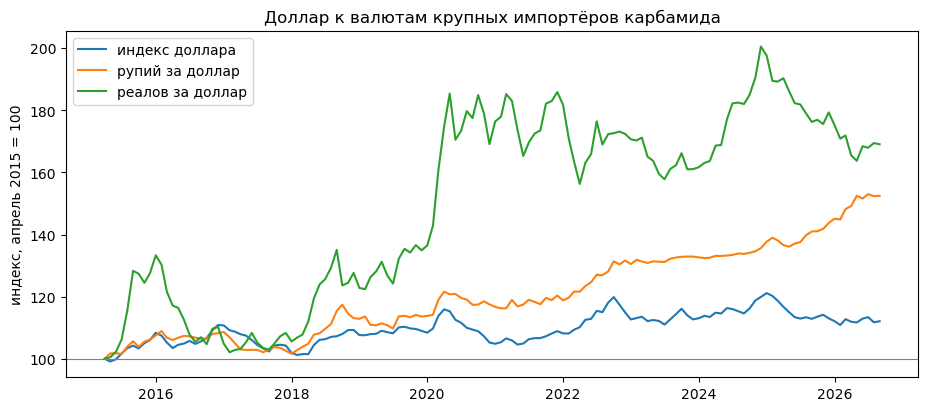

In [23]:
fx = prices[["urea_price", "gas_europe"]].join(fred[["usd_index", "inr_per_usd", "brl_per_usd"]])
train = fx.loc[:"2023-09"]
changes = np.log(train).diff()
target_change = np.log(train["urea_price"].shift(-1) / train["urea_price"])
links = pd.DataFrame({
    "тот же месяц": changes.corrwith(changes["urea_price"]),
    "→ цена в след. месяце": changes.corrwith(target_change),
}).drop(["urea_price", "gas_europe"]).round(2)
print("Корреляции месячных изменений с ценой карбамида (трейн, порог ≈ ±0,2):")
print(links.to_string())

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(fx.index, fx["usd_index"] / fx["usd_index"].iloc[0] * 100, label="индекс доллара")
ax1.plot(fx.index, fx["inr_per_usd"] / fx["inr_per_usd"].iloc[0] * 100, label="рупий за доллар")
ax1.plot(fx.index, fx["brl_per_usd"] / fx["brl_per_usd"].iloc[0] * 100, label="реалов за доллар")
ax1.axhline(100, color="gray", linewidth=0.8)
ax1.set_ylabel("индекс, апрель 2015 = 100")
ax1.set_title("Доллар к валютам крупных импортёров карбамида")
ax1.legend()
plt.show()

**Главный результат: месячные изменения валютных курсов почти не связаны с ценой карбамида.**

С 2015 по 2026 год доллар подорожал к индийской рупии и особенно к бразильскому реалу. Поэтому для бразильского фермера карбамид подорожал сильнее, чем в долларах. Однако корреляции месячных изменений курсов с ценой карбамида близки к нулю, и все они ниже порога случайности 0,2. Вероятная причина в том, что курс влияет на спрос медленно, через сезон закупок, а не в следующем месяце. Поэтому курсы мы рассматриваем только как кандидатов в признаки с длинным запаздыванием или в виде изменения за 6 или 12 месяцев и проверим их на базовых моделях.

### Итог по оборотному капиталу

| Составляющая | Значение | Как используем |
|---|---|---|
| Дни цикла (DSO + DIO) | около 60 дней у производителей США, плюс рейс у экспортёров | параметр расчёта; длительность рейса уточняем по данным Саши |
| Ставка | ставка ФРС плюс 2 процентных пункта: от 2 до 7% в период с 2015 по 2026 год | ряд по месяцам |
| Затраты на финансирование | от 1 до 6 долларов на тонну, около 1% надбавки | признак financing_cost_usd_t |
| Валютные курсы | доллар вырос к рупии и реалу; месячной связи с ценой карбамида нет | кандидаты в признаки с длинным запаздыванием |
| Авансы покупателей | от 10 до 30 дней выручки (CF Industries, CVR Partners) | уменьшают дни цикла примерно до 56 |
| Реальная ставка по долгу | от 5 до 7% (медиана 5,2%) | используем вместо допущения «ставка ФРС плюс 2 процентных пункта» |
| Число судов (Comtrade) | Саудовская Аравия: от 100 до 110 судов в год, около 18 миллионов долларов затрат | формула затрат в год на реальных объёмах |
| Доля финансирования в валовой марже | от 2 до 8%, в слабые годы от 10 до 35% | связь логистики и прибыльности завода |

**Ограничения.** Длительность рейса и погрузки является допущением, пока нет данных Саши по PortWatch. Дни цикла взяты у американских производителей, потому что у экспортёров Ближнего Востока нет отчётности в EDGAR. Надбавка банка тоже является допущением. Кредиторская задолженность CF Industries включает начисленные обязательства, поэтому её DPO завышен.

## 3. Выводы и их использование в проекте

**Главный результат: внешние данные подтверждают, что целевая цена отражает реальную торговлю, и дают два кандидата в признаки шоков предложения: ограничения экспорта Китая и стоимость доставки.**

1. **Котировке можно доверять.** Средняя цена экспорта Саудовской Аравии по данным Comtrade почти совпадает с котировкой Pink Sheet: корреляция около 0,95, разница около 24 долларов за тонну. Значит, целевая переменная отражает реальные сделки.
2. **Китай является главным источником шока предложения.** После ограничений осенью 2021 года экспорт Китая упал примерно вдвое, а в 2024 году почти до нуля. Кандидат в признаки: флаг или объём ограничений экспорта Китая, который собирает команда.
3. **Стоимость доставки заметно растёт в кризис.** Разница цен CIF и FOB составляет от 15 до 22 долларов за тонну в спокойные годы и около 45 долларов в 2022 году. Кандидат в признаки: стоимость доставки вместе с данными о трафике судов из PortWatch.
4. **Данные Comtrade приходят с запаздыванием.** Задержка публикации составляет от 1 до 5 месяцев, а по Китаю данные есть только до декабря 2024 года. Поэтому в модели можно использовать только те значения, которые известны на дату прогноза, то есть со сдвигом на срок задержки.
5. **Финансирование составляет около 1% цены.** Цикл оборотного капитала длится около 56 дней, реальная ставка составляет около 5%, поэтому затраты составляют около 4 долларов на тонну. Цену эти затраты почти не двигают. Однако в слабые годы они съедают от 10 до 35% маржи небольших производителей, а при ставках России (до 21%) и Бразилии (до 15%) составляют от 14 до 20 долларов на тонну.
6. **Валютные курсы.** Месячной связи курсов с ценой карбамида нет, потому что курс влияет на спрос медленно, через сезон закупок. В модели курсы можно использовать только как кандидатов с длинным запаздыванием (изменение за 6 или 12 месяцев) и нужно проверить их на базовых моделях.